# RT-IoT2022 - Exploratory Data Analysis

The goal of this notebook is to analyze the RT-IoT2022 dataset. In particular, we want to understand:

- The size of the dataset
- The available features
- The data types
- The presence of missing values or duplicates
- The distribution of normal and anomalous traffic

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("../data/raw/RT_IOT2022.csv")
print("Dataset loaded successfully")

In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

In [ ]:
df.head()
print(df.columns.tolist())
df.info()

In [ ]:
missing_value = df.isnull().sum()
print("Total missing values:", missing_value.sum())
missing_value[missing_value > 0]

In [ ]:
duplicates = df.duplicated().sum()
print("Number of duplicated rows:", duplicates)

In [ ]:
df = df.drop(columns=["Unnamed: 0"])
print("New dataset shape:", df.shape)

In [ ]:
numeric_columns = df.select_dtypes(include=["number"]).columns
categorical_columns = df.select_dtypes(include=["object"]).columns

print("Number of numeric columns:", len(numeric_columns))
print("Number of categorical columns:", len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns.tolist())

print(df["Attack_type"].unique())
print("Number of traffic classes:", df["Attack_type"].nunique())

attack_counts = df["Attack_type"].value_counts()
print(attack_counts)

attack_percentages = df["Attack_type"].value_counts(normalize=True) * 100
print(attack_percentages)

In [ ]:
attack_counts.plot(kind="bar", figsize=(12,6))

plt.title("Distribution of Traffic Classes")
plt.xlabel("Traffic Class")
plt.ylabel("Number of samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df["Attack_type"].unique()
df["Attack_type"].value_counts()

In [37]:
normal_classes = ["MQTT_Publish", "Thing_Speak", "Wipro_bulb"]

df["Label"] = df["Attack_type"].apply(
    lambda x: "Normal" if x in normal_classes else "Anomaly"
)
print(df["Label"].value_counts())

label_percentages = df["Label"].value_counts(normalize = True) * 100
print(label_percentages)

Label
Anomaly    110610
Normal      12507
Name: count, dtype: int64
Label
Anomaly    89.84137
Normal     10.15863
Name: proportion, dtype: float64


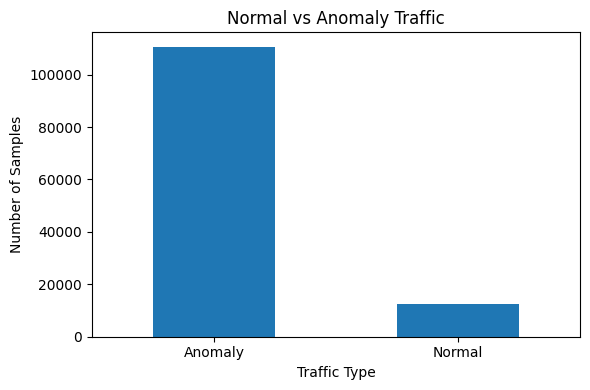

,id.orig_p,id.resp_p,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,...,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size
count,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,123117.000000,1.231170e+05,1.231170e+05,1.231170e+05,...,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,1.231170e+05,123117.000000,123117.000000,123117.000000
mean,34639.258738,1014.305092,3.809566,2.268826,1.909509,1.471218,0.820260,3.518063e+05,3.517620e+05,7.035683e+05,...,1.481354e+05,2.353599e+04,1.616655e+06,1.701956e+06,3.517644e+06,1.664985e+06,4.550183e+04,6118.905123,2739.776018,751.647514
std,19070.620354,5256.371994,130.005408,22.336565,33.018311,19.635196,32.293948,3.707645e+05,3.708015e+05,7.415634e+05,...,1.613007e+06,1.477935e+06,8.809396e+06,9.252337e+06,1.229508e+08,9.007064e+06,1.091361e+06,18716.313861,10018.848534,6310.183843
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,17702.000000,21.000000,0.000001,1.000000,1.000000,1.000000,0.000000,7.454354e+01,7.288927e+01,1.490871e+02,...,9.536740e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
50%,37221.000000,21.000000,0.000004,1.000000,1.000000,1.000000,0.000000,2.467238e+05,2.467238e+05,4.934475e+05,...,4.053116e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
75%,50971.000000,21.000000,0.000005,1.000000,1.000000,1.000000,0.000000,5.242880e+05,5.242880e+05,1.048576e+06,...,5.006790e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,64.000000,0.000000,64.000000
max,65535.000000,65389.000000,21728.335578,4345.000000,10112.000000,4345.000000,10105.000000,1.048576e+06,1.048576e+06,2.097152e+06,...,4.374931e+08,4.774862e+08,3.000000e+08,3.000000e+08,2.096777e+10,3.000000e+08,1.208029e+08,65535.000000,65535.000000,65535.000000


In [39]:
label_counts = df["Label"].value_counts()
label_counts.plot(kind="bar", figsize=(6,4))

plt.title("Normal vs Anomaly Traffic")
plt.xlabel("Traffic Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()
df[numeric_columns].describe()

In [ ]:
print("Protocol values:")
print(df["proto"].value_counts())

print("\nService values:")
print(df(["service"].value_counts()))

Up to now, we can clearly see that the RT-IoT dataset contains 123117 samples and 83 input features after removing the unnecessary index column.

The original target contains 12 traffic classes divided into:

- 3 normal traffic classes
- 9 attack classes

For the anomaly detection task, the three normal classes are:

- # MQTT_Publish
- # Thing_Speak
- # Wipro_bulb

while all the other classes are considered anomalous. According to the results, the dataset is strongly dominated by anomalous class, especially DOS_SYN_Hping